# Cas pratiques 6 à 10 : calculs et simulations

Chaque section reprend un cas pratique du cours. Faites les calculs à la main d'abord, puis vérifiez ici.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## Fonctions utiles

In [2]:
import itertools
z = stats.norm.ppf
def var_tvar_discrete(valeurs, probas, alpha):
    valeurs, probas = np.asarray(valeurs, float), np.asarray(probas, float)
    F = np.cumsum(probas); i = np.argmax(F >= alpha - 1e-12); v = valeurs[i]; m = valeurs > v
    return v, (np.sum(valeurs[m]*probas[m]) + v*(F[i] - alpha)) / (1 - alpha)

def mesures(S, alpha=0.995):
    v = np.quantile(S, alpha, method='inverted_cdf')
    return S.mean(), v, S[S > v].mean(), v - S.mean()

## Cas 6 : bonus-malus Poisson-Gamma

In [3]:
alpha, beta, cout = 2, 20, 400_000
NB = stats.nbinom(alpha, beta/(beta + 1)); P = stats.poisson(alpha/beta)
print('Prime a priori :', alpha/beta*cout)
print('Binomiale negative : E =', NB.mean(), 'Var =', NB.var(), 'P(0) =', NB.pmf(0), 'P(>=2) =', NB.sf(1))
print('Poisson            : P(0) =', P.pmf(0), 'P(>=2) =', P.sf(1), '| rapport :', NB.sf(1)/P.sf(1))
for k, t in [(0, 3), (1, 3), (2, 3), (0, 10)]:
    lam = (alpha + k)/(beta + t); Z = t/(beta + t)
    print(f'{k} sinistre(s) en {t} ans : frequence {lam:.4f}, prime {lam*cout:,.0f}, coefficient {lam/0.1:.2f}, Z = {Z:.3f}')
print('Regle simple : 3 ans sans sinistre', 0.95**3, '| 2 sinistres en 3 ans', 0.95*1.25**2)
# Verification par simulation : assures tires au hasard
r = np.random.default_rng(1); lam = r.gamma(alpha, 1/beta, 1_000_000); N3 = r.poisson(lam*3)
print('Simulation : frequence moyenne des assures avec 2 sinistres en 3 ans =', lam[N3 == 2].mean())

Prime a priori : 40000.0
Binomiale negative : E = 0.10000000000000012 Var = 0.10500000000000012 P(0) = 0.9070294784580494 P(>=2) = 0.006586761688802519
Poisson            : P(0) = 0.9048374180359595 P(>=2) = 0.004678840160444474 | rapport : 1.4077765990998932
0 sinistre(s) en 3 ans : frequence 0.0870, prime 34,783, coefficient 0.87, Z = 0.130
1 sinistre(s) en 3 ans : frequence 0.1304, prime 52,174, coefficient 1.30, Z = 0.130
2 sinistre(s) en 3 ans : frequence 0.1739, prime 69,565, coefficient 1.74, Z = 0.130
0 sinistre(s) en 10 ans : frequence 0.0667, prime 26,667, coefficient 0.67, Z = 0.333
Regle simple : 3 ans sans sinistre 0.8573749999999999 | 2 sinistres en 3 ans 1.484375
Simulation : frequence moyenne des assures avec 2 sinistres en 3 ans = 0.17364542378772513


## Cas 7 : risque de change d'un importateur

In [4]:
S0, s, T, Q = 600, 0.08, 0.25, 1e6
m, sd = -s**2*T/2, s*np.sqrt(T)
ST = stats.lognorm(s=sd, scale=S0*np.exp(m))
q95, q99 = ST.ppf(0.95), ST.ppf(0.99)
print('E[S_T] =', ST.mean(), '| q95 =', q95, '| q99 =', q99)
print('VaR du surcout : 95 %', (q95 - S0)*Q, '| 99 %', (q99 - S0)*Q)
tv = S0*np.exp(m + sd**2/2)*stats.norm.cdf(sd - z(0.95))/0.05
print('TVaR 95 % du surcout :', (tv - S0)*Q, '| P(S_T > 610) :', ST.sf(610))
K = 610; d1 = (np.log(S0/K) + s**2*T/2)/sd; d2 = d1 - sd
prime = S0*stats.norm.cdf(d1) - K*stats.norm.cdf(d2)
print('d1, d2 :', d1, d2, '| prime par dollar :', prime, '| verification :', ST.expect(lambda x: max(x - K, 0)))
print('Option : cout au quantile 95 % =', (min(q95, K) + prime)*Q, '| cout moyen =', (ST.mean() - prime + prime)*Q)

E[S_T] = 599.9999999999999 | q95 = 640.2916657618182 | q99 = 657.9859445150416
VaR du surcout : 95 % 40291665.76181819 | 99 % 57985944.515041634
TVaR 95 % du surcout : 51156125.746768795 | P(S_T > 610) : 0.3324229174315838
d1, d2 : -0.3932325487802646 -0.43323254878026457 | prime par dollar : 5.466339858726087 | verification : 5.466339858966972
Option : cout au quantile 95 % = 615466339.8587261 | cout moyen = 599999999.9999999


## Cas 8 : risque de taux d'un portefeuille obligataire

In [5]:
P0, D, C, sig = 1e9, 4.5, 25, 0.0006
s1 = D*sig*P0; s10 = s1*np.sqrt(10)
print('Ecart-type 1 jour :', s1, '| VaR 1 j :', z(0.99)*s1, '| VaR 10 j :', z(0.99)*s10, '| ES 97,5 % 10 j :', stats.norm.pdf(z(0.975))/0.025*s10)
for dy in [0.02, -0.02]:
    print(f'Choc {dy*1e4:+.0f} pb : duration {-D*dy*P0/1e6:+.1f} M | avec convexite {(-D*dy + 0.5*C*dy**2)*P0/1e6:+.1f} M')
print('Duration maximale pour VaR 10 j <= 12 M :', 12e6/(z(0.99)*sig*np.sqrt(10)*P0))
# Verification par simulation de l'approximation avec convexite
r = np.random.default_rng(2); dy = r.normal(0, sig*np.sqrt(10), 1_000_000)
L = -(-D*dy + 0.5*C*dy**2)*P0; print('VaR 10 j simulee avec convexite :', np.quantile(L, 0.99))

Ecart-type 1 jour : 2699999.9999999995 | VaR 1 j : 6281139.259910269 | VaR 10 j : 19862706.362020794 | ES 97,5 % 10 j : 19960510.167876042
Choc +200 pb : duration -90.0 M | avec convexite -85.0 M
Choc -200 pb : duration +90.0 M | avec convexite +95.0 M
Duration maximale pour VaR 10 j <= 12 M : 2.7186627550036517
VaR 10 j simulee avec convexite : 19602422.19803627


## Cas 9 : risque de concentration

In [6]:
def loi_pertes(EAD, PD, LGD):
    pertes = [e*l for e, l in zip(EAD, LGD)]; d = {}
    for scen in itertools.product([0, 1], repeat=len(EAD)):
        p = np.prod([q if x else 1 - q for x, q in zip(scen, PD)])
        L = round(sum(x*l for x, l in zip(scen, pertes)), 6); d[L] = d.get(L, 0) + p
    v = np.array(sorted(d)); return v, np.array([d[x] for x in v])

v, p = loi_pertes([500, 200, 100], [0.01, 0.03, 0.05], [0.45, 0.60, 0.70])
EL = sum(e*q*l for e, q, l in zip([500, 200, 100], [0.01, 0.03, 0.05], [0.45, 0.60, 0.70]))
print('EL :', EL); print(np.column_stack([v, p.round(6), np.cumsum(p).round(6)]))
for a in [0.95, 0.995]: print('Concentre', a, var_tvar_discrete(v, p, a))
v2, p2 = loi_pertes([100]*5 + [200, 100], [0.01]*5 + [0.03, 0.05], [0.45]*5 + [0.60, 0.70])
for a in [0.95, 0.995]: print('Divise  ', a, var_tvar_discrete(v2, p2, a))
print('Capital : concentre', var_tvar_discrete(v, p, 0.995)[0] - EL, '| divise', var_tvar_discrete(v2, p2, 0.995)[0] - EL)

EL : 9.35
[[0.00000e+00 9.12285e-01 9.12285e-01]
 [7.00000e+01 4.80150e-02 9.60300e-01]
 [1.20000e+02 2.82150e-02 9.88515e-01]
 [1.90000e+02 1.48500e-03 9.90000e-01]
 [2.25000e+02 9.21500e-03 9.99215e-01]
 [2.95000e+02 4.85000e-04 9.99700e-01]
 [3.45000e+02 2.85000e-04 9.99985e-01]
 [4.15000e+02 1.50000e-05 1.00000e+00]]
Concentre 0.95 (np.float64(70.0), np.float64(134.19899999999984))
Concentre 0.995 (np.float64(225.0), np.float64(239.1999999999934))
Divise   0.95 (np.float64(70.0), np.float64(106.00199395636467))
Divise   0.995 (np.float64(120.0), np.float64(154.91226369639236))
Capital : concentre 215.65 | divise 110.65


## Cas 10 : catastrophe naturelle et réassurance
Simulation d'un million d'années (quelques secondes).

Courants : E = 145883273.96954027 sigma = 17007392.88833815 VaR normale = 189691414.94829082
Inondation : E annuelle = 20000000.0 | P(>300 M) = 0.022222222222222223 | P(>1 Md) = 0.002


Courants   [np.float64(145.9), np.float64(195.1), np.float64(202.9), np.float64(49.2)]
Inondation [np.float64(20.2), np.float64(634.1), np.float64(1287.6), np.float64(614.0)]
Total      [np.float64(166.0), np.float64(780.5), np.float64(1433.5), np.float64(614.4)]
Prime pure tranche : simulee 4.712173141100694 | exacte 4.666666666666667
Apres reassurance [np.float64(161.3), np.float64(464.3), np.float64(882.0), np.float64(302.9)]


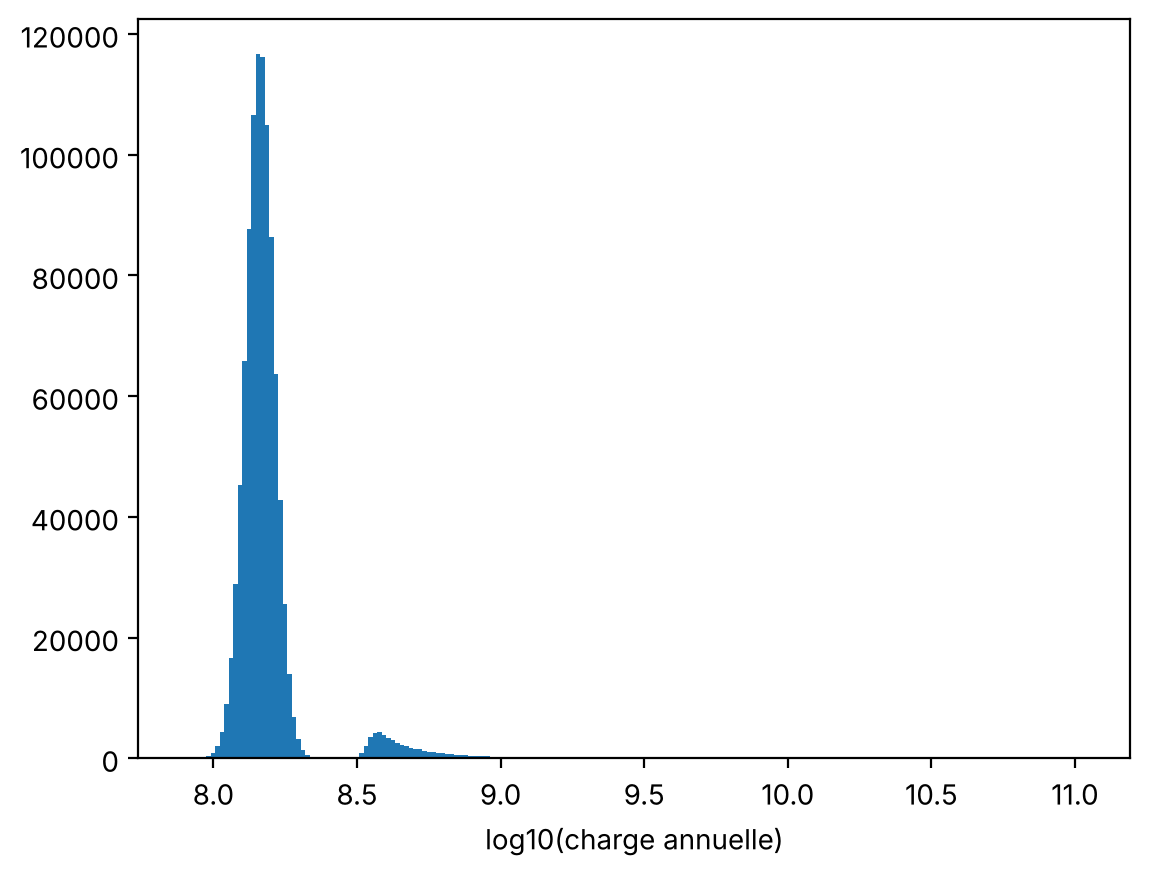

In [7]:
EX, EX2 = np.exp(13.5), np.exp(28)
print('Courants : E =', 200*EX, 'sigma =', np.sqrt(200*EX2), 'VaR normale =', 200*EX + z(0.995)*np.sqrt(200*EX2))
Pa = stats.pareto(b=2, scale=200e6)
print('Inondation : E annuelle =', 0.05*Pa.mean(), '| P(>300 M) =', 0.05*Pa.sf(300e6), '| P(>1 Md) =', 0.05*Pa.sf(1e9))
rng10 = np.random.default_rng(42); n = 1_000_000
N = rng10.poisson(200, n); X = rng10.lognormal(13, 1, N.sum())
courants = np.bincount(np.repeat(np.arange(n), N), weights=X, minlength=n)
inond = np.where(rng10.random(n) < 0.05, Pa.rvs(n, random_state=rng10), 0.0)
total = courants + inond
for nom, S in [('Courants', courants), ('Inondation', inond), ('Total', total)]:
    print(f'{nom:10s}', [round(x/1e6, 1) for x in mesures(S)])
tranche = np.clip(inond - 300e6, 0, 700e6)
print('Prime pure tranche : simulee', tranche.mean()/1e6, '| exacte', 0.05*200**2*(1/300 - 1/1000))
net = total - tranche; print('Apres reassurance', [round(x/1e6, 1) for x in mesures(net)])
plt.hist(np.log10(total), bins=200); plt.xlabel('log10(charge annuelle)'); plt.show()